## Figure 1 — Pipeline

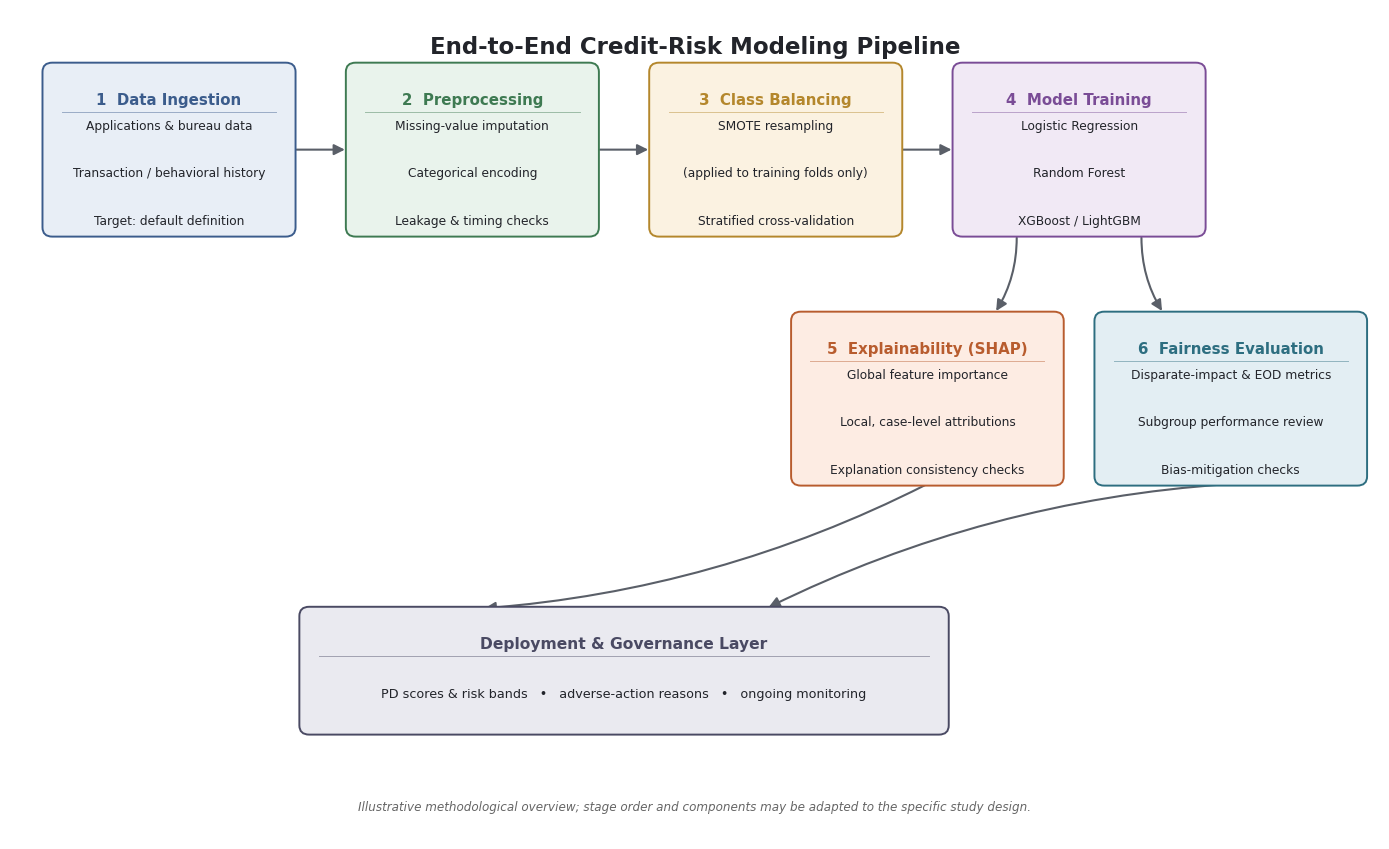

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})

fig, ax = plt.subplots(figsize=(14, 8.6))
ax.set_xlim(0, 14)
ax.set_ylim(0, 9)
ax.axis("off")

c_data, e_data = "#E8EEF6", "#3B5C8C"
c_prep, e_prep = "#E9F3EC", "#3E7A52"
c_smote, e_smote = "#FBF2E1", "#B4872C"
c_model, e_model = "#F1E9F5", "#7A4C96"
c_shap, e_shap = "#FDECE3", "#B85C2E"
c_fair, e_fair = "#E3EEF3", "#2D6E80"
c_deploy, e_deploy = "#EAEAF0", "#4A4A63"
txt_dark, arrow_c = "#22242A", "#5A5F68"

def box(x, y, w, h, title, lines, fc, ec, fs_title=10.8, fs_line=8.8):
    b = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.018,rounding_size=0.10",
                       linewidth=1.4, edgecolor=ec, facecolor=fc, zorder=2)
    ax.add_patch(b)
    ax.text(x+w/2, y+h-0.30, title, ha="center", va="top", fontsize=fs_title,
            fontweight="bold", color=ec, zorder=3)
    ax.plot([x+0.18, x+w-0.18], [y+h-0.52, y+h-0.52],
            color=ec, linewidth=0.7, alpha=0.45, zorder=3)
    n = len(lines)
    body_top, body_bot = y+h-0.66, y+0.16
    ys = [(body_top+body_bot)/2] if n == 1 else [
        body_top-i*(body_top-body_bot)/(n-1) for i in range(n)
    ]
    for line, ly in zip(lines, ys):
        ax.text(x+w/2, ly, line, ha="center", va="center",
                fontsize=fs_line, color=txt_dark, zorder=3)
    return dict(x=x, y=y, w=w, h=h)

def h_arrow(b1, b2):
    p1 = (b1["x"]+b1["w"], b1["y"]+b1["h"]/2)
    p2 = (b2["x"], b2["y"]+b2["h"]/2)
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=16,
                                 linewidth=1.5, color=arrow_c, zorder=1,
                                 shrinkA=2, shrinkB=2))

w1, h1, gap1 = 2.55, 1.85, 0.55
y1, x0 = 6.55, 0.35

b_data = box(x0, y1, w1, h1, "1  Data Ingestion",
             ["Applications & bureau data", "Transaction / behavioral history", "Target: default definition"],
             c_data, e_data)

b_prep = box(x0+(w1+gap1), y1, w1, h1, "2  Preprocessing",
             ["Missing-value imputation", "Categorical encoding", "Leakage & timing checks"],
             c_prep, e_prep)

b_smote = box(x0+2*(w1+gap1), y1, w1, h1, "3  Class Balancing",
              ["SMOTE resampling", "(applied to training folds only)", "Stratified cross-validation"],
              c_smote, e_smote)

b_model = box(x0+3*(w1+gap1), y1, w1, h1, "4  Model Training",
              ["Logistic Regression", "Random Forest", "XGBoost / LightGBM"],
              c_model, e_model)

for left, right in [(b_data,b_prep),(b_prep,b_smote),(b_smote,b_model)]:
    h_arrow(left, right)

w2, h2, y2 = 2.75, 1.85, 3.85
x_shap = x0+3*(w1+gap1)-(w2-w1)/2-1.55
x_fair = x0+3*(w1+gap1)-(w2-w1)/2+1.55

b_shap = box(x_shap, y2, w2, h2, "5  Explainability (SHAP)",
             ["Global feature importance", "Local, case-level attributions", "Explanation consistency checks"],
             c_shap, e_shap)

b_fair = box(x_fair, y2, w2, h2, "6  Fairness Evaluation",
             ["Disparate-impact & EOD metrics", "Subgroup performance review", "Bias-mitigation checks"],
             c_fair, e_fair)

# Corrected: only the two deliberate curved arrows are used.
ax.add_patch(FancyArrowPatch(
    (b_model["x"]+b_model["w"]*0.25, b_model["y"]),
    (b_shap["x"]+b_shap["w"]*0.75, b_shap["y"]+b_shap["h"]),
    arrowstyle="-|>", mutation_scale=16, linewidth=1.5, color=arrow_c,
    zorder=1, connectionstyle="arc3,rad=-0.15", shrinkA=2, shrinkB=2))

ax.add_patch(FancyArrowPatch(
    (b_model["x"]+b_model["w"]*0.75, b_model["y"]),
    (b_fair["x"]+b_fair["w"]*0.25, b_fair["y"]+b_fair["h"]),
    arrowstyle="-|>", mutation_scale=16, linewidth=1.5, color=arrow_c,
    zorder=1, connectionstyle="arc3,rad=0.15", shrinkA=2, shrinkB=2))

w3, h3, y3 = 6.6, 1.35, 1.15
x3 = x0+(3*(w1+gap1)+w1)/2-w3/2

b_deploy = box(x3, y3, w3, h3, "Deployment & Governance Layer",
               ["PD scores & risk bands   •   adverse-action reasons   •   ongoing monitoring"],
               c_deploy, e_deploy, fs_title=11.2, fs_line=9.2)

for source, target_x, rad in [(b_shap, 0.28, -0.10), (b_fair, 0.72, 0.10)]:
    ax.add_patch(FancyArrowPatch(
        (source["x"]+source["w"]*0.5, source["y"]),
        (b_deploy["x"]+b_deploy["w"]*target_x, b_deploy["y"]+b_deploy["h"]),
        arrowstyle="-|>", mutation_scale=16, linewidth=1.5, color=arrow_c,
        zorder=1, connectionstyle=f"arc3,rad={rad}", shrinkA=2, shrinkB=2))

ax.text(7, 8.72, "End-to-End Credit-Risk Modeling Pipeline", ha="center", va="top",
        fontsize=16.5, fontweight="bold", color=txt_dark)
ax.text(7, 0.35,
        "Illustrative methodological overview; stage order and components may be adapted to the specific study design.",
        ha="center", va="center", fontsize=8.6, color="#666666", style="italic")

plt.tight_layout()
plt.savefig("../plots/credit_risk_pipeline.png", dpi=300, bbox_inches="tight", facecolor="white")
# plt.savefig("../plots/credit_risk_pipeline.pdf", bbox_inches="tight", facecolor="white")
plt.show()

## Figure 2 — Trilemma

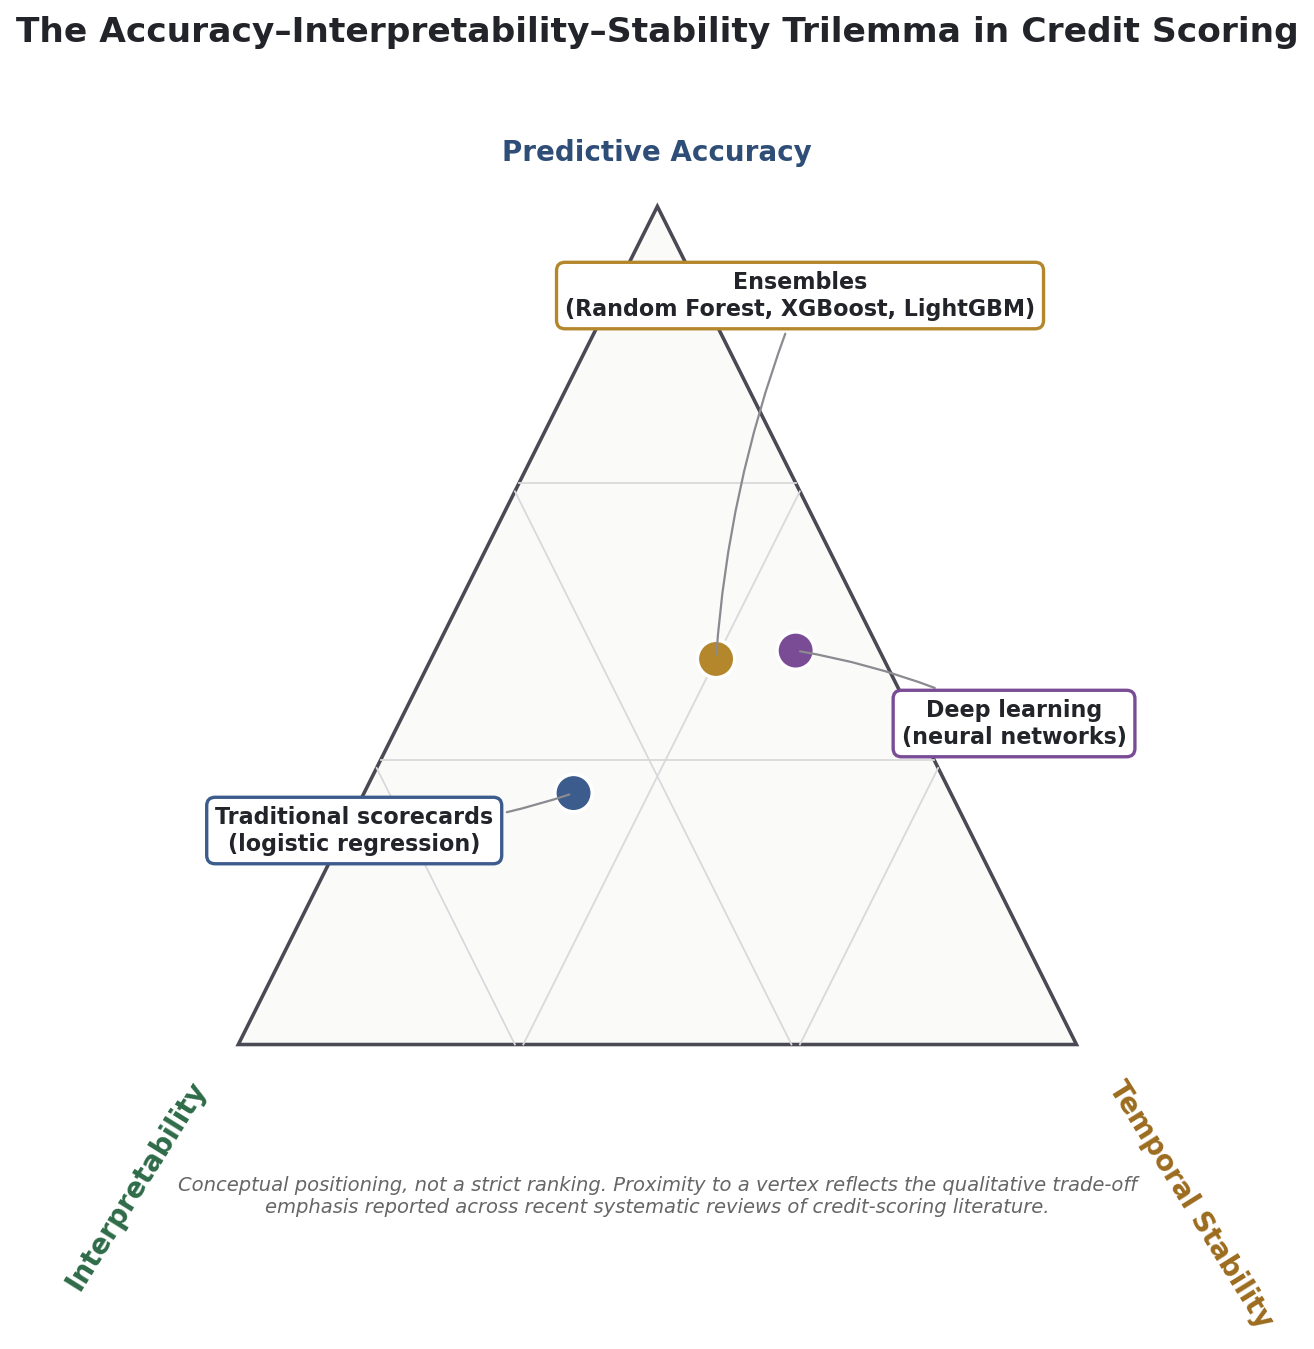

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon, Circle
 
plt.rcParams.update({"font.family": "DejaVu Sans"})
 
fig, ax = plt.subplots(figsize=(9.2, 8.6))
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.14, 1.14)
ax.axis("off")
ax.set_aspect("equal")
 
txt_dark = "#22242A"
grid_c = "#D9D9DD"
 
V_acc  = np.array([0.5, 1.0])
V_int  = np.array([0.03, 0.06])
V_stab = np.array([0.97, 0.06])
 
tri = Polygon([V_acc, V_int, V_stab], closed=True, facecolor="#FAFAF8",
              edgecolor="#4A4A55", linewidth=1.6, zorder=1)
ax.add_patch(tri)
 
# Subtle internal guide lines
for frac in (0.33, 0.66):
    p1 = V_acc + frac * (V_int - V_acc); p2 = V_acc + frac * (V_stab - V_acc)
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color=grid_c, linewidth=0.8, zorder=1)
    p3 = V_int + frac * (V_acc - V_int); p4 = V_int + frac * (V_stab - V_int)
    ax.plot([p3[0], p4[0]], [p3[1], p4[1]], color=grid_c, linewidth=0.8, zorder=1)
    p5 = V_stab + frac * (V_acc - V_stab); p6 = V_stab + frac * (V_int - V_stab)
    ax.plot([p5[0], p6[0]], [p5[1], p6[1]], color=grid_c, linewidth=0.8, zorder=1)
 
# Vertex labels (rotated along edges, offset outward — no overlap with triangle)
ax.text(V_acc[0], V_acc[1] + 0.045, "Predictive Accuracy", ha="center", va="bottom",
        fontsize=12.5, fontweight="bold", color="#2E4E78")
ax.text(V_int[0] - 0.03, V_int[1] - 0.035, "Interpretability", ha="right", va="top",
        fontsize=12.5, fontweight="bold", color="#2E6B48", rotation=58)
ax.text(V_stab[0] + 0.03, V_stab[1] - 0.035, "Temporal Stability", ha="left", va="top",
        fontsize=12.5, fontweight="bold", color="#9C6B1E", rotation=-58)
 
def bary(w_acc, w_int, w_stab):
    s = w_acc + w_int + w_stab
    w_acc, w_int, w_stab = w_acc / s, w_int / s, w_stab / s
    return w_acc * V_acc + w_int * V_int + w_stab * V_stab
 
models = [
    {"name": "Traditional scorecards\n(logistic regression)",
     "w": (0.30, 0.45, 0.25), "color": "#3B5C8C", "label_xy": (0.16, 0.30)},
    {"name": "Ensembles\n(Random Forest, XGBoost, LightGBM)",
     "w": (0.46, 0.20, 0.34), "color": "#B4872C", "label_xy": (0.66, 0.90)},
    {"name": "Deep learning\n(neural networks)",
     "w": (0.47, 0.10, 0.43), "color": "#7A4C96", "label_xy": (0.90, 0.42)},
]
 
for m in models:
    xy = bary(*m["w"])
    ax.add_patch(Circle(xy, 0.021, facecolor=m["color"], edgecolor="white",
                         linewidth=1.6, zorder=4))
    lx, ly = m["label_xy"]
    ax.annotate(m["name"], xy=xy, xytext=(lx, ly),
                fontsize=10, ha="center", va="center", color=txt_dark,
                fontweight="bold", zorder=5,
                arrowprops=dict(arrowstyle="-", color="#8A8A90", lw=1.0,
                                 connectionstyle="arc3,rad=0.08"),
                bbox=dict(boxstyle="round,pad=0.38", facecolor="white",
                          edgecolor=m["color"], linewidth=1.5))
 
ax.text(0.5, -0.01, "", ha="center")  # spacer
 
ax.set_title("The Accuracy\u2013Interpretability\u2013Stability Trilemma in Credit Scoring",
             fontsize=15.5, fontweight="bold", color=txt_dark, pad=18)
 
ax.text(0.5, -0.11,
        "Conceptual positioning, not a strict ranking. Proximity to a vertex reflects the qualitative trade-off\n"
        "emphasis reported across recent systematic reviews of credit-scoring literature.",
        ha="center", va="center", fontsize=8.8, color="#666666", style="italic")

plt.tight_layout()
plt.savefig("../plots/trilemma.png",dpi=300,bbox_inches="tight",facecolor="white")
# plt.savefig("../plots/trilemma.pdf",bbox_inches="tight",facecolor="white")
plt.show()

## Figure 3 — XAI comparison

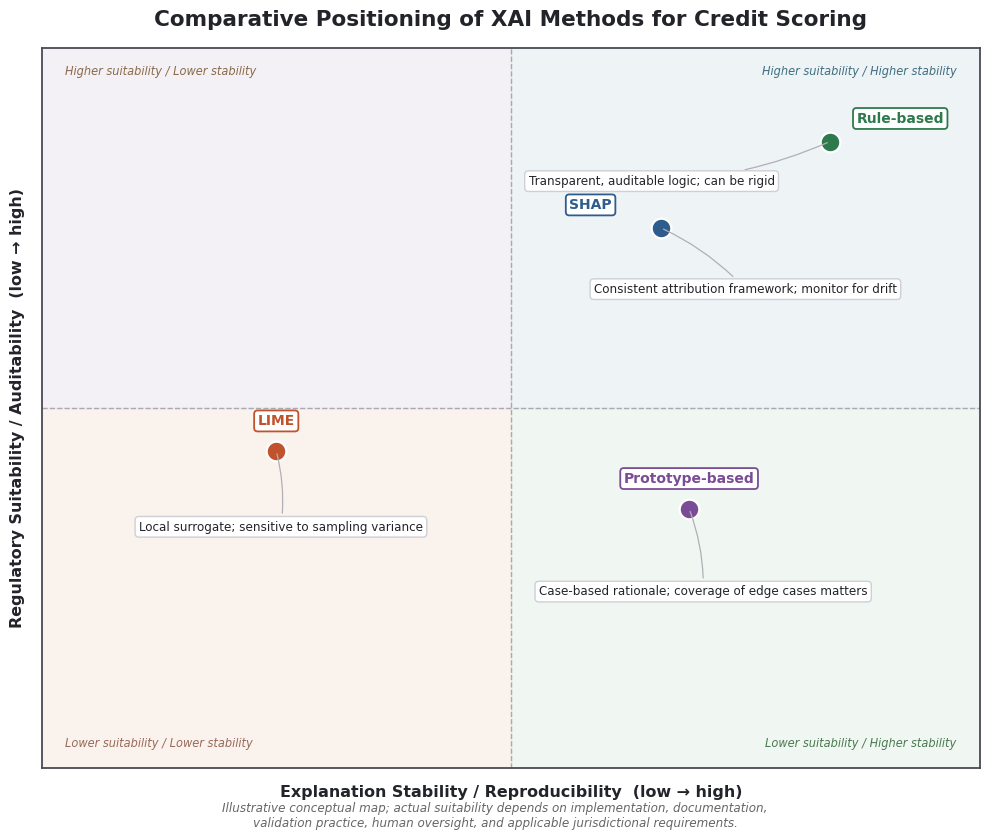

In [3]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "DejaVu Sans"})
fig, ax = plt.subplots(figsize=(10, 8.2))
ax.set_xlim(0,10); ax.set_ylim(0,10)

txt_dark = "#22242A"

ax.axvspan(0,5,0,0.5,color="#F6E9DE",alpha=0.55,zorder=0)
ax.axvspan(5,10,0,0.5,color="#E4EFE6",alpha=0.55,zorder=0)
ax.axvspan(0,5,0.5,1,color="#EAE6F0",alpha=0.55,zorder=0)
ax.axvspan(5,10,0.5,1,color="#E1EAEF",alpha=0.55,zorder=0)

ax.axhline(5,color="#A9A9AF",linewidth=1.0,linestyle="--",zorder=1)
ax.axvline(5,color="#A9A9AF",linewidth=1.0,linestyle="--",zorder=1)

ax.set_xlabel("Explanation Stability / Reproducibility  (low → high)",
              fontsize=11.5,fontweight="bold",labelpad=12,color=txt_dark)
ax.set_ylabel("Regulatory Suitability / Auditability  (low → high)",
              fontsize=11.5,fontweight="bold",labelpad=12,color=txt_dark)
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(True); spine.set_color("#4A4A55"); spine.set_linewidth(1.3)

ax.text(0.25,9.75,"Higher suitability / Lower stability",ha="left",va="top",
        fontsize=8.2,color="#8A6A4A",style="italic")
ax.text(9.75,9.75,"Higher suitability / Higher stability",ha="right",va="top",
        fontsize=8.2,color="#3E6E80",style="italic")
ax.text(0.25,0.25,"Lower suitability / Lower stability",ha="left",va="bottom",
        fontsize=8.2,color="#9A6A5A",style="italic")
ax.text(9.75,0.25,"Lower suitability / Higher stability",ha="right",va="bottom",
        fontsize=8.2,color="#4A7A50",style="italic")

methods = [
    {"name":"LIME","x":2.5,"y":4.4,"color":"#C0532B","name_dx":0.0,"name_dy":0.42,
     "note":"Local surrogate; sensitive to sampling variance","dx":0.05,"dy":-1.05},
    {"name":"SHAP","x":6.6,"y":7.5,"color":"#2E5C8C","name_dx":-0.75,"name_dy":0.32,
     "note":"Consistent attribution framework; monitor for drift","dx":0.9,"dy":-0.85},
    {"name":"Rule-based","x":8.4,"y":8.7,"color":"#2E7A4C","name_dx":0.75,"name_dy":0.32,
     "note":"Transparent, auditable logic; can be rigid","dx":-1.9,"dy":-0.55},
    {"name":"Prototype-based","x":6.9,"y":3.6,"color":"#7A4C96","name_dx":0.0,"name_dy":0.42,
     "note":"Case-based rationale; coverage of edge cases matters","dx":0.15,"dy":-1.15}
]

for m in methods:
    x,y=m["x"],m["y"]
    ax.scatter(x,y,s=200,color=m["color"],edgecolor="white",linewidth=1.6,zorder=5)
    ax.text(x+m["name_dx"],y+m["name_dy"],m["name"],ha="center",va="center",
            fontsize=10,fontweight="bold",color=m["color"],zorder=6,
            bbox=dict(boxstyle="round,pad=0.25",facecolor="white",
                      edgecolor=m["color"],linewidth=1.3))
    ax.annotate(m["note"],xy=(x,y),xytext=(x+m["dx"],y+m["dy"]),fontsize=8.6,
                ha="center",va="center",color=txt_dark,zorder=6,
                arrowprops=dict(arrowstyle="-",color="#B0B0B6",lw=0.9,
                                connectionstyle="arc3,rad=0.1"),
                bbox=dict(boxstyle="round,pad=0.32",facecolor="white",
                          edgecolor="#CFCFD6",linewidth=1.0))

ax.set_title("Comparative Positioning of XAI Methods for Credit Scoring",
             fontsize=15.5,fontweight="bold",pad=16,color=txt_dark)

fig.text(0.5,-0.015,
         "Illustrative conceptual map; actual suitability depends on implementation, documentation,\n"
         "validation practice, human oversight, and applicable jurisdictional requirements.",
         ha="center",fontsize=8.6,color="#666666",style="italic")

plt.tight_layout()
plt.savefig("../plots/xai_credit_scoring_comparison.png",dpi=300,bbox_inches="tight",facecolor="white")
# plt.savefig("../plots/xai_credit_scoring_comparison.pdf",bbox_inches="tight",facecolor="white")
plt.show()